# MDPs — Dynamic Programming

Dynamic programming for MDPs with a known model: value iteration and policy iteration.

## Goal
Find an optimal policy $\pi^*$ when the model $T$ and $R$ are **known** (dynamic programming).

## Implemented below
1. GridWorld MDP
2. Value iteration
3. Policy extraction
4. Policy iteration
5. Comparison + plot


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## MDP

An MDP is a tuple $\langle S, A, T, R, \gamma \rangle$:

- $S$: states, $A$: actions
- $T^a_{ss'} = P(s'\mid s,a)$: transition probabilities
- $R^a_s = \mathbb{E}[r\mid s,a]$: expected immediate reward
- $\gamma \in [0,1)$: discount factor

**Objective:** maximize expected discounted return
$$G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \cdots$$

Arrays below use shapes `T[s, a, s']` and `R[s, a]`.

In [2]:
class MDP:
    def __init__(self, states, actions, transition_probabilities, rewards, discount_factor):
        self.states = list(states)
        self.actions = list(actions)
        self.transition_probabilities = transition_probabilities  # T[s, a, s']
        self.rewards = rewards                                    # R[s, a]
        self.discount_factor = discount_factor

    @property
    def n_states(self):
        return len(self.states)

    @property
    def n_actions(self):
        return len(self.actions)

## GridWorld

Small $3\times 4$ grid (inherits from `MDP`):

```text
.  .  .  +1
.  .  .  -1
S  .  .  .
```

- Actions: N, E, S, W
- Noise: intended direction with prob. $1-\textit{noise}$, slip left/right with $\textit{noise}/2$ each
- Terminals are absorbing; reward is collected on entry
- Borders / walls: stay in place

In [3]:
ACTIONS = {
    0: (-1, 0),  # N
    1: (0, 1),   # E
    2: (1, 0),   # S
    3: (0, -1),  # W
}

class GridWorld(MDP):
    def __init__(self, height, width, terminals, walls=(), start=None,
                 step_reward=0.0, noise=0.2, gamma=0.9):
        # 1) store grid-specific stuff
        self.height = height
        self.width = width
        self.terminals = dict(terminals)   # keep rewards! (see bug below)
        self.walls = set(walls)
        self.start = start
        self.step_reward = step_reward
        self.noise = noise

        # 2) build dynamics
        T, R = self._build_dynamics()

        # 3) initialize the MDP parent
        states = [s for s in range(height * width) if s not in self.walls]
        actions = list(range(4))
        super().__init__(states, actions, T, R, gamma)

    def to_s(self, r, c):
        return r * self.width + c
    
    def to_rc(self, s):
        return divmod(s, self.width)

    def _in_bounds(self, r, c):
        return 0 <= r < self.height and 0 <= c < self.width

    def _next_cell(self, s, action):
        """Deterministic intended move, with walls / borders = stay."""
        if s in self.terminals:
            return s
        r, c = self.to_rc(s)
        dr, dc = ACTIONS[action]
        nr, nc = r + dr, c + dc
        if not self._in_bounds(nr, nc) or self.to_s(nr, nc) in self.walls:
            return s
        return self.to_s(nr, nc)

    def _build_dynamics(self):
        nS, nA = self.height * self.width, 4
        T = np.zeros((nS, nA, nS))
        R = np.zeros((nS, nA))
        for s in range(nS):
            if s in self.walls:
                continue  # unused state
            if s in self.terminals:
                for a in range(nA):
                    T[s, a, s] = 1.0
                    R[s, a] = 0.0
                continue
            for a in range(nA):
                # intended + left + right (relative to a)
                intents = [a, (a - 1) % 4, (a + 1) % 4]
                probs = [1 - self.noise, self.noise / 2, self.noise / 2]
                for action_dir, p in zip(intents, probs):
                    s2 = self._next_cell(s, action_dir)
                    T[s, a, s2] += p
                    # reward depends on landing cell
                    if s2 in self.terminals:
                        R[s, a] += p * self.terminals[s2]
                    else:
                        R[s, a] += p * self.step_reward
        return T, R

In [4]:
gw = GridWorld(3, 4, terminals={3: 1.0, 7: -1.0}, start=8)
print(gw.transition_probabilities.shape)
print(isinstance(gw, MDP))  # True

(12, 4, 12)
True


In [5]:
T = gw.transition_probabilities
# non-wall states: each (s,a) should sum to 1
for s in gw.states:
    for a in gw.actions:
        assert np.isclose(T[s, a].sum(), 1.0), (s, a, T[s, a].sum())
print("T OK")

T OK


## Value iteration

We want the optimal values $v^*(s) = \max_\pi v_\pi(s)$. They satisfy the **Bellman optimality** equation:

$$v^*(s) = \max_a \Big( R^a_s + \gamma \sum_{s'} T^a_{ss'}\, v^*(s') \Big)$$

**Algorithm:** start from $V \equiv 0$, repeatedly apply that backup until the largest change $\Delta < \varepsilon$.

Terminals stay at $V=0$ (reward already counted on entry).

In [6]:
def value_iteration(mdp, epsilon=1e-2):
    V = np.zeros(mdp.transition_probabilities.shape[0])  # one entry per grid cell
    gamma = mdp.discount_factor
    T, R = mdp.transition_probabilities, mdp.rewards
    while True:
        delta = 0.0
        for s in mdp.states:
            if s in getattr(mdp, "terminals", {}):  # optional: skip / keep V=0
                continue
            v = V[s]
            
            q = R[s] + gamma * T[s] @ V
            V[s] = np.max(q)
            delta = max(delta, abs(v - V[s]))
        if delta < epsilon:
            break
    return V

## Policy extraction

Value iteration gives $V \approx v^*$, not the actions. For each state, pick the greedy action:

$$q(s,a) = R^a_s + \gamma \sum_{s'} T^a_{ss'}\, V(s'), \qquad \pi(s) = \arg\max_a q(s,a)$$

Same one-step lookahead as VI; VI keeps $\max_a$, extraction keeps $\arg\max_a$.

In [7]:
def extract_policy(mdp, V):
    gamma = mdp.discount_factor
    T, R = mdp.transition_probabilities, mdp.rewards
    nS = T.shape[0]
    pi = np.zeros(nS, dtype=int)

    for s in mdp.states:
        if s in getattr(mdp, "terminals", {}):
            pi[s] = -1  # no action
            continue
        q = R[s] + gamma * T[s] @ V
        pi[s] = np.argmax(q)
    return pi

## Run VI + extract $\pi$

Actions: `0=N`, `1=E`, `2=S`, `3=W`, `-1` = terminal.

In [8]:
V = value_iteration(gw)
pi = extract_policy(gw, V)

print(V.reshape(gw.height, gw.width).round(3))
print(pi.reshape(gw.height, gw.width))  # 0=N, 1=E, 2=S, 3=W, -1=terminal

[[0.705 0.815 0.943 0.   ]
 [0.626 0.701 0.642 0.   ]
 [0.554 0.603 0.545 0.321]]
[[ 1  1  1 -1]
 [ 0  0  0 -1]
 [ 0  0  0  3]]


## Policy iteration

Alternate until the policy stops changing:

1. **Evaluate** $\pi$: solve for $v_\pi$ (no $\max$ — only action $\pi(s)$)
$$v_\pi(s) = R^{\pi(s)}_s + \gamma \sum_{s'} T^{\pi(s)}_{ss'}\, v_\pi(s')$$
2. **Improve**: set $\pi \leftarrow$ greedy w.r.t. $v_\pi$ (same as policy extraction)

Same optimum as value iteration; works explicitly on $\pi$.

In [9]:
def policy_evaluation(mdp, pi, epsilon=1e-6):
    V = np.zeros(mdp.transition_probabilities.shape[0])
    gamma = mdp.discount_factor
    T, R = mdp.transition_probabilities, mdp.rewards

    while True:
        delta = 0.0
        for s in mdp.states:
            if s in getattr(mdp, "terminals", {}):
                continue
            v = V[s]
            a = pi[s]
            V[s] = R[s, a] + gamma * T[s, a] @ V
            delta = max(delta, abs(v - V[s]))
        if delta < epsilon:
            break
    return V

In [ ]:
def policy_iteration(mdp):
    pi = np.zeros(mdp.transition_probabilities.shape[0], dtype=int)

    while True:
        V = policy_evaluation(mdp, pi)
        new_pi = extract_policy(mdp, V)
        if np.all(pi == new_pi):
            return V, pi
        pi = new_pi



## Compare VI vs PI

Both methods should find the same $\pi^*$ (and nearly the same $V$).

In [11]:
V_vi = value_iteration(gw, epsilon=1e-6)
pi_vi = extract_policy(gw, V_vi)

V_pi, pi_pi = policy_iteration(gw)

print(np.allclose(V_vi, V_pi, atol=1e-3))
print(pi_vi.reshape(3, 4))
print(pi_pi.reshape(3, 4))

True
[[ 1  1  1 -1]
 [ 0  0  0 -1]
 [ 0  0  0  3]]
[[ 1  1  1 -1]
 [ 0  0  0 -1]
 [ 0  0  0  3]]


## Visualization

Heatmap of $V(s)$ (color) and arrows for $\pi(s)$.

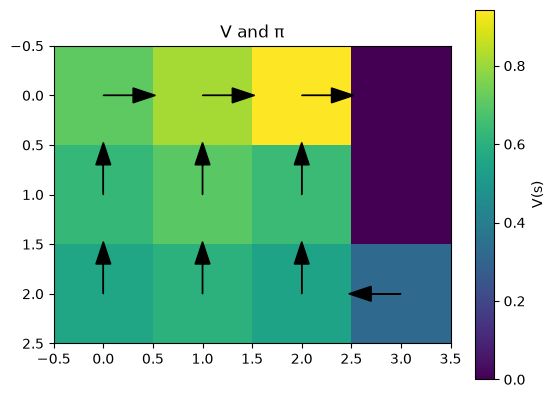

In [12]:
def plot_grid(mdp, V, pi):
    H, W = mdp.height, mdp.width
    grid = V.reshape(H, W)
    fig, ax = plt.subplots()
    im = ax.imshow(grid, origin="upper")
    plt.colorbar(im, ax=ax, label="V(s)")

    arrows = {0: (0, -0.3), 1: (0.3, 0), 2: (0, 0.3), 3: (-0.3, 0)}  # N,E,S,W
    for s in mdp.states:
        if s in mdp.terminals:
            continue
        r, c = mdp.to_rc(s)
        dx, dy = arrows[pi[s]]
        ax.arrow(c, r, dx, dy, head_width=0.15, color="black")
    ax.set_title("V and π")
    plt.show()

plot_grid(gw, V_vi, pi_vi)

## References

1. S. Airiau. *Apprentissage par renforcement*. M2 IASD, Université Paris Dauphine. Lecture 2: *MDP – Itération sur les valeurs – itération sur les politiques*. [https://www.lamsade.dauphine.fr/~airiau/Teaching/M2-IASDapp-RL/](https://www.lamsade.dauphine.fr/~airiau/Teaching/M2-IASDapp-RL/)
